In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [5]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_vehicle.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_baseline_power_empa.nc")

In [7]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,2.428,0.354,1.752,3.078,0.011,0.009,1116.0,1693.0,1.00
gtyp[fa/fa],0.400,0.545,-0.646,1.402,0.017,0.013,1042.0,1444.0,1.00
age[Young],0.071,0.524,-0.915,1.053,0.014,0.011,1351.0,1680.0,1.00
sex[M],-0.221,0.497,-1.152,0.699,0.013,0.009,1360.0,1787.0,1.01
"gtyp:age[fa/fa, Young]",-0.082,0.702,-1.473,1.176,0.020,0.016,1253.0,1483.0,1.00
"gtyp:sex[fa/fa, M]",-1.005,0.703,-2.307,0.323,0.019,0.014,1312.0,1716.0,1.00
1|rat_sigma,0.973,0.147,0.730,1.256,0.005,0.003,926.0,1682.0,1.01
sigma_Intercept,-0.184,0.031,-0.245,-0.128,0.001,0.001,3206.0,2613.0,1.00
sigma_band[low_frequency],0.920,0.051,0.826,1.015,0.001,0.001,3275.0,2436.0,1.00


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.756,0.292,1.233,2.326,0.008,0.008,1164.0,1478.0,1.01
gtyp[fa/fa],0.332,0.438,-0.522,1.146,0.013,0.009,1116.0,1475.0,1.00
age[Young],-0.301,0.413,-1.084,0.485,0.011,0.009,1385.0,1556.0,1.00
sex[M],0.064,0.395,-0.675,0.843,0.011,0.008,1248.0,1783.0,1.00
"gtyp:age[fa/fa, Young]",0.585,0.573,-0.468,1.659,0.016,0.014,1319.0,1453.0,1.00
"gtyp:sex[fa/fa, M]",-1.341,0.568,-2.490,-0.329,0.017,0.012,1117.0,1577.0,1.00
1|rat_sigma,0.808,0.118,0.610,1.034,0.004,0.002,886.0,1705.0,1.00
sigma_Intercept,-0.100,0.039,-0.176,-0.029,0.001,0.001,2210.0,2241.0,1.00
sigma_band[low_frequency],0.560,0.070,0.431,0.695,0.001,0.001,2468.0,2246.0,1.00


## Single effects

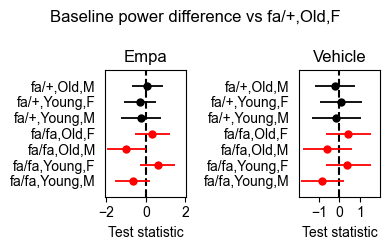

In [17]:
interactions_ts_vehicle, interactions_ts_empa = (
    {
        "fa/fa,Young,M": (
            idata.posterior["gtyp"] 
            + idata.posterior["age"]
            + idata.posterior["sex"]
            + idata.posterior["gtyp:age"]
            + idata.posterior["gtyp:sex"]
        ),
        "fa/fa,Young,F": idata.posterior["gtyp"] + idata.posterior["age"] + idata.posterior["gtyp:age"],
        "fa/fa,Old,M": idata.posterior["gtyp"] + idata.posterior["gtyp:sex"],
        "fa/fa,Old,F": idata.posterior["gtyp"],
        "fa/+,Young,M": idata.posterior["age"] + idata.posterior["sex"],
        "fa/+,Young,F": idata.posterior["age"],
        "fa/+,Old,M": idata.posterior["sex"],
    } for idata in (idata_vehicle, idata_empa)
)
f, axes = plt.subplots(1, 2, figsize=(4, 2.5))
axes[1] = forestplot_oz(axes[1], interactions_ts_vehicle);
axes[1].set_title("Vehicle");

axes[0] = forestplot_oz(axes[0], interactions_ts_empa);
axes[0].set_title("Empa");
f.suptitle("Baseline power difference vs fa/+,Old,F")
f.tight_layout()

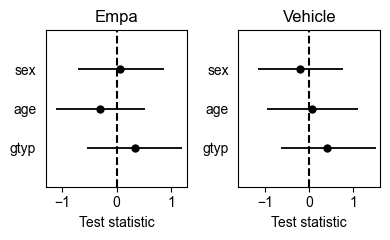

In [11]:
single_ts_vehicle, single_ts_empa = (
    {
        "gtyp": idata.posterior["gtyp"],
        "age": idata.posterior["age"],
        "sex": idata.posterior["sex"],
    } for idata in (idata_vehicle, idata_empa)
)
f, axes = plt.subplots(1, 2, figsize=(4, 2.5))
axes[1] = forestplot_oz(axes[1], single_ts_vehicle);
axes[1].set_title("Vehicle");

axes[0] = forestplot_oz(axes[0], single_ts_empa);
axes[0].set_title("Empa");
f.tight_layout()